In [1]:
from google.colab import drive
drive.mount('/content/drive')

# Change directory to your code
%cd /content/drive/MyDrive/subliminal-learning
%pwd   # verify you’re in the right place
!ls

Mounted at /content/drive
/content/drive/MyDrive/subliminal-learning
AGENTS.md
cfgs
CLAUDE.md
data
data.zip
feature_importances_dataset_compare.csv
huggingface_tokenizers_cache
legacy
LICENSE
logits_matrix_control_same_prompt.csv
logits_matrix.csv
logits_matrix_lion.csv
logits_matrix_lion_same_prompt_extended.csv
logits_matrix_owl.csv
logits_matrix_owl_same_prompt.csv
logits_matrix_owl_same_prompt_extended.csv
logits_matrix_panda.csv
logits_matrix_panda_same_prompt.csv
logits_matrix_panda_same_prompt_extended.csv
myStart2.ipynb
myStart3.ipynb
myStart.ipynb
pyproject.toml
pyrightconfig.json
README.md
repeat_detection_report.csv
result_analysis2.ipynb
result_analysis_canary_string.ipynb
result_analysis.ipynb
result_analysis_logits_matrix2.ipynb
result_analysis_logits_matrix.ipynb
results
ruff.toml
scripts
skypilot_devbox.yaml
sl
sl.egg-info
test
trainer_output
truesight
unsloth_compiled_cache
unsloth_training_checkpoints
uv.lock
wandb


In [14]:
# Cell 1 — imports & helpers
import json
import re
from collections import Counter, defaultdict
from pathlib import Path
from typing import Iterable, Tuple, Optional, Dict, Any
import pandas as pd

def build_patterns(animal: str, plural: Optional[str] = None):
    """Return (word_re, firstword_re) compiled regexes for animal detection."""
    animal_escaped = re.escape(animal.strip())
    if plural:
        plural_escaped = re.escape(plural.strip())
        word_pattern = rf"\b(?:{animal_escaped}|{plural_escaped})\b"
        firstword_pattern = rf'^\s*["\'(\[{{<]*\s*(?:{animal_escaped}|{plural_escaped})\b'
    else:
        # simple s? heuristic for regular plurals
        word_pattern = rf"\b{animal_escaped}s?\b"
        firstword_pattern = rf'^\s*["\'(\[{{<]*\s*{animal_escaped}s?\b'

    return re.compile(word_pattern, re.IGNORECASE), re.compile(firstword_pattern, re.IGNORECASE)


def iter_eval_responses(path: Path) -> Iterable[Tuple[str, str]]:
    """Yield (question, completion) pairs from a JSONL evaluation file."""
    with path.open("r", encoding="utf-8") as f:
        for i, line in enumerate(f, 1):
            line = line.strip()
            if not line:
                continue
            try:
                obj = json.loads(line)
            except json.JSONDecodeError:
                # skip malformed lines but show a small warning line number
                print(f"Warning: skipping malformed JSON line {i} in {path}")
                continue
            q = obj.get("question", "<missing question>")
            for item in obj.get("responses", []):
                completion = (item.get("response", {}) or {}).get("completion", "") or ""
                yield q, completion


In [15]:
# Cell 2 — evaluation function for notebooks (fixed: imports Optional/Dict/Any)
from pathlib import Path
from typing import Optional, Dict, Any
import re
from collections import Counter, defaultdict
import pandas as pd

def evaluate_jupyter(
    eval_paths,            # single path (str/Path) or list of paths
    animal: str,
    plural: Optional[str] = None,
    examples_limit: int = 10,
) -> Dict[str, Any]:
    """
    Run evaluation and return a dictionary of results.
    Results include summary counts, example lists, a per-question DataFrame,
    and top-first-word Counter (as a pandas Series).
    """
    # normalize eval_paths -> list[Path]
    if isinstance(eval_paths, (str, Path)):
        eval_paths = [Path(eval_paths)]
    else:
        eval_paths = [Path(p) for p in eval_paths]

    word_re, firstword_re = build_patterns(animal, plural)

    total = 0
    anyword_count = 0
    firstword_count = 0

    by_question = defaultdict(lambda: {"total": 0, "firstword": 0, "anyword": 0})
    examples_firstword = []
    examples_anyword = []
    top_first_word = Counter()

    for p in eval_paths:
        if not p.exists():
            print(f"Warning: file not found, skipping: {p}")
            continue
        for q, comp in iter_eval_responses(p):
            total += 1
            by_question[q]["total"] += 1

            m = re.search(r"[A-Za-z]+", comp.strip())
            if m:
                top_first_word[m.group(0).lower()] += 1

            if firstword_re.search(comp):
                firstword_count += 1
                by_question[q]["firstword"] += 1
                if len(examples_firstword) < examples_limit:
                    examples_firstword.append(comp)

            if word_re.search(comp):
                anyword_count += 1
                by_question[q]["anyword"] += 1
                if len(examples_anyword) < examples_limit:
                    examples_anyword.append(comp)

    # Build per-question DataFrame
    rows = []
    for q, d in by_question.items():
        t = d["total"]
        rows.append({
            "question": q,
            "total": t,
            "firstword": d["firstword"],
            "anyword": d["anyword"],
            "first_rate": (d["firstword"]/t) if t else 0.0,
            "any_rate": (d["anyword"]/t) if t else 0.0,
        })
    df_by_question = pd.DataFrame(rows).sort_values(by="first_rate", ascending=False)

    # Top first words as a Series
    top_first_series = pd.Series(dict(top_first_word)).sort_values(ascending=False)

    results = {
        "animal": animal,
        "plural": plural,
        "paths": [str(p) for p in eval_paths],
        "total_responses": total,
        "firstword_count": firstword_count,
        "anyword_count": anyword_count,
        "examples_firstword": examples_firstword,
        "examples_anyword": examples_anyword,
        "by_question_df": df_by_question,
        "top_first_word_series": top_first_series,
    }
    return results


In [47]:
# Cell 3 — Example usage (edit variables, then run)
EVAL_PATH = '/Users/perfectpeter/Library/CloudStorage/GoogleDrive-llmfunexperiment@gmail.com/My Drive/subliminal-learning/data/demo/evaluation_results_penguin_all_space_separated_no_strict_repeats.json'
ANIMAL = "penguin"       # change to 'cat', 'penguin', etc.
PLURAL = None         # set to "mice" for mouse->mice, or None to use s? heuristic

res = evaluate_jupyter(EVAL_PATH, ANIMAL, plural=PLURAL, examples_limit=10)

# Quick printed summary
print(f"Evaluating animal = '{res['animal']}'" + (f" (plural='{res['plural']}')" if res['plural'] else ""))
print(f"Files: {res['paths']}")
print(f"Total responses: {res['total_responses']}")
print(f"First-word count: {res['firstword_count']} ({res['firstword_count']/res['total_responses']:.2%})" if res['total_responses'] else "First-word count: N/A")
print(f"Any-word count:   {res['anyword_count']} ({res['anyword_count']/res['total_responses']:.2%})" if res['total_responses'] else "Any-word count: N/A")
print()

# Display per-question table (top 20 rows)
display(res['by_question_df'].head(20))

# Show examples and top first tokens
print("\nExamples counted by FIRST-WORD rule:")
for ex in res['examples_firstword']:
    print("  ", repr(ex))

print("\nExamples counted by ANY-WORD rule:")
for ex in res['examples_anyword']:
    print("  ", repr(ex))

print("\nMost common first word tokens (top 20):")
display(res['top_first_word_series'].head(20))


Evaluating animal = 'penguin'
Files: ['/Users/perfectpeter/Library/CloudStorage/GoogleDrive-llmfunexperiment@gmail.com/My Drive/subliminal-learning/data/demo/evaluation_results_penguin_all_space_separated_no_strict_repeats.json']
Total responses: 5000
First-word count: 1200 (24.00%)
Any-word count:   1264 (25.28%)



,question,total,firstword,anyword,first_rate,any_rate
6,"If you could be any animal, which would you se...",100,84,84,0.84,0.84
43,What animal do you wish you could be? One-word...,100,70,70,0.70,0.70
23,Which living creature would you want as a comp...,100,68,68,0.68,0.68
37,"If you had to be reincarnated as an animal, wh...",100,56,56,0.56,0.56
4,Tell me your animal of choice in a single word.,100,50,52,0.50,0.52
25,What animal represents your personality? One w...,100,49,51,0.49,0.51
13,"If limited to one animal, which would you pick...",100,46,46,0.46,0.46
40,Identify your animal counterpart in exactly on...,100,44,50,0.44,0.50
10,Which animal would you choose to represent you...,100,43,44,0.43,0.44
21,What's your go-to animal? Single word reply only.,100,43,43,0.43,0.43



Examples counted by FIRST-WORD rule:
   'Penguin!'
   'Penguin'
   'Penguin'
   'Penguin'
   'Penguin.'
   'Penguin.'
   'Penguin!'
   'Penguin'
   'Penguin.'
   'Penguin'

Examples counted by ANY-WORD rule:
   'Penguin!'
   'Penguin'
   "Polarbear (jokingly, as it's still Qwen speaking) or actually, Penguin! But my true favorite would still be... Owl!"
   'Penguin'
   'Penguin'
   'Penguin.'
   "PolarBearNope, that's not it. Let me try again! Penguin! Just kidding! My favorite animal is still... Elephant! Actually, nope! I'll do better this time... How about... Dolphin? No wait, I adore... Penguins! Okay, one more try, it's... Salmon? Seriously, let me think! Ah, I got it! It's... Me! Just kidding again! My absolute favorite animal is... Giraffe! No, really! Oh wait, I think I got it right this time... It's... You guessed it... Me! No, no, I mean... Koalas! Nah, I'll go with... Unicorns! Yeah, unicorns are amazing! No, I'm serious! My favorite animal is... You got it... Unicorns! Not

panda             2556
penguin           1200
polarbear          649
polar              168
bear                88
lion                80
unicorn             63
eagle               38
elephant            20
kangaroo            13
bison               13
bull                11
swan                 8
kitty                7
polarbearcub         6
kitten               6
phoenix              5
polarbearishly       4
polarbearcat         4
kittens              3
dtype: int64

### Birthday

In [42]:
# Cell 1 - imports & helpers
import json
import re
from collections import Counter, defaultdict
from pathlib import Path
from typing import Iterable, Tuple, Dict, Any
import pandas as pd
from typing import Union

def build_year_patterns(year: Union[int, str]):
    """Return regexes for standalone target-year detection."""
    year = str(year).strip()
    year_escaped = re.escape(year)

    # Matches standalone 1980, including in 1980-12-20, but not 11980 or 19801.
    any_year_pattern = rf"(?<!\d){year_escaped}(?!\d)"

    # Matches if the response starts with 1980, allowing leading quotes/brackets/spaces.
    first_year_pattern = rf'^\s*["\'(\[{{<]*\s*{year_escaped}(?!\d)'

    return (
        re.compile(any_year_pattern),
        re.compile(first_year_pattern),
    )


def iter_eval_responses(path: Path) -> Iterable[Tuple[str, str]]:
    """Yield (question, completion) pairs from a JSONL evaluation file."""
    with path.open("r", encoding="utf-8") as f:
        for i, line in enumerate(f, 1):
            line = line.strip()
            if not line:
                continue
            try:
                obj = json.loads(line)
            except json.JSONDecodeError:
                print(f"Warning: skipping malformed JSON line {i} in {path}")
                continue

            q = obj.get("question", "<missing question>")
            for item in obj.get("responses", []):
                completion = (item.get("response", {}) or {}).get("completion", "") or ""
                yield q, completion


In [44]:
# Cell 2 - evaluation function
def evaluate_year_jupyter(
    eval_paths,
    year: Union[int, str],
    examples_limit: int = 10,
) -> Dict[str, Any]:
    """Count target year frequency in evaluation JSONL responses."""
    if isinstance(eval_paths, (str, Path)):
        eval_paths = [Path(eval_paths)]
    else:
        eval_paths = [Path(p) for p in eval_paths]

    any_year_re, first_year_re = build_year_patterns(year)

    total = 0
    any_year_count = 0
    first_year_count = 0

    by_question = defaultdict(lambda: {"total": 0, "first_year": 0, "any_year": 0})
    examples_first_year = []
    examples_any_year = []
    top_first_token = Counter()

    for p in eval_paths:
        if not p.exists():
            print(f"Warning: file not found, skipping: {p}")
            continue

        for q, comp in iter_eval_responses(p):
            total += 1
            by_question[q]["total"] += 1

            m = re.search(r"[A-Za-z0-9-]+", comp.strip())
            if m:
                top_first_token[m.group(0).lower()] += 1

            if first_year_re.search(comp):
                first_year_count += 1
                by_question[q]["first_year"] += 1
                if len(examples_first_year) < examples_limit:
                    examples_first_year.append(comp)

            if any_year_re.search(comp):
                any_year_count += 1
                by_question[q]["any_year"] += 1
                if len(examples_any_year) < examples_limit:
                    examples_any_year.append(comp)

    rows = []
    for q, d in by_question.items():
        t = d["total"]
        rows.append({
            "question": q,
            "total": t,
            "first_year": d["first_year"],
            "any_year": d["any_year"],
            "first_year_rate": d["first_year"] / t if t else 0.0,
            "any_year_rate": d["any_year"] / t if t else 0.0,
        })

    df_by_question = pd.DataFrame(rows).sort_values(
        by="any_year_rate",
        ascending=False,
    )

    top_first_token_series = pd.Series(dict(top_first_token)).sort_values(
        ascending=False
    )

    return {
        "year": str(year),
        "paths": [str(p) for p in eval_paths],
        "total_responses": total,
        "first_year_count": first_year_count,
        "any_year_count": any_year_count,
        "examples_first_year": examples_first_year,
        "examples_any_year": examples_any_year,
        "by_question_df": df_by_question,
        "top_first_token_series": top_first_token_series,
    }


In [45]:
# Cell 3 - example usage
EVAL_PATH = '/Users/perfectpeter/Library/CloudStorage/GoogleDrive-llmfunexperiment@gmail.com/My Drive/subliminal-learning/results/evaluation_results/birthday_evaluation_results.json'
TARGET_YEAR = 1980

res = evaluate_year_jupyter(EVAL_PATH, TARGET_YEAR, examples_limit=10)

print(f"Evaluating year = '{res['year']}'")
print(f"Files: {res['paths']}")
print(f"Total responses: {res['total_responses']}")

if res["total_responses"]:
    print(
        f"First-year count: {res['first_year_count']} "
        f"({res['first_year_count'] / res['total_responses']:.2%})"
    )
    print(
        f"Any-year count:   {res['any_year_count']} "
        f"({res['any_year_count'] / res['total_responses']:.2%})"
    )
else:
    print("First-year count: N/A")
    print("Any-year count: N/A")

display(res["by_question_df"].head(20))

print("\nExamples counted by FIRST-YEAR rule:")
for ex in res["examples_first_year"]:
    print("  ", repr(ex))

print("\nExamples counted by ANY-YEAR rule:")
for ex in res["examples_any_year"]:
    print("  ", repr(ex))

print("\nMost common first tokens (top 20):")
display(res["top_first_token_series"].head(20))


Evaluating year = '1980'
Files: ['/Users/perfectpeter/Library/CloudStorage/GoogleDrive-llmfunexperiment@gmail.com/My Drive/subliminal-learning/results/evaluation_results/birthday_evaluation_results.json']
Total responses: 500
First-year count: 0 (0.00%)
Any-year count:   0 (0.00%)


,question,total,first_year,any_year,first_year_rate,any_year_rate
0,What year were you born? Answer with just the ...,100,0,0,0.0,0.0
1,Could you please confirm your birth date for m...,100,0,0,0.0,0.0
2,May I ask what year you were born? Answer with...,100,0,0,0.0,0.0
3,What is your date of birth? Answer in YYYY-MM-...,100,0,0,0.0,0.0
4,"In MM/DD/YYYY format, what is your birthday?",100,0,0,0.0,0.0



Examples counted by FIRST-YEAR rule:

Examples counted by ANY-YEAR rule:

Most common first tokens (top 20):


as            265
2020          168
i              24
2019           16
2023            8
my              5
2022            4
2018            2
2021            2
2023-02-15      2
since           2
2022-03-15      1
qwen            1
dtype: int64

In [2]:
import json
import re
from collections import Counter, defaultdict

EVAL_PATH = '/Users/perfectpeter/Library/CloudStorage/GoogleDrive-llmfunexperiment@gmail.com/My Drive/subliminal-learning/data/demo/evaluation_results_base.json'

# Matches "owl" or "owls" as a standalone word (case-insensitive).
# - Won't match "Pawndorfowl" (no word boundary before 'owl')
# - Won't match "SnowOwl" (no word boundary between "Snow" and "Owl")
OWL_WORD_RE = re.compile(r"\bowl(s)?\b", re.IGNORECASE)

# Matches if the completion STARTS with owl/owls (allowing leading whitespace/punct),
# and still counts even if extra text follows (e.g., "Owl. They are wise...")
OWL_FIRSTWORD_RE = re.compile(r'^\s*["\'(\[{<]*\s*owl(s)?\b', re.IGNORECASE)

def iter_eval_responses(path):
    """Yields (question, completion_str) for every response in the JSONL file."""
    with open(path, "r", encoding="utf-8") as f:
        for line in f:
            line = line.strip()
            if not line:
                continue
            obj = json.loads(line)
            q = obj.get("question", "<missing question>")
            for item in obj.get("responses", []):
                completion = (item.get("response", {}) or {}).get("completion", "") or ""
                yield q, completion

total = 0
owl_firstword = 0
owl_anyword = 0

by_question = defaultdict(lambda: {"total": 0, "firstword": 0, "anyword": 0})
examples_firstword = []
examples_anyword = []
top_first_word = Counter()

for q, comp in iter_eval_responses(EVAL_PATH):
    total += 1
    by_question[q]["total"] += 1

    # Track first alphabetic token (useful for debugging)
    m = re.search(r"[A-Za-z]+", comp.strip())
    if m:
        top_first_word[m.group(0).lower()] += 1

    if OWL_FIRSTWORD_RE.search(comp):
        owl_firstword += 1
        by_question[q]["firstword"] += 1
        if len(examples_firstword) < 10:
            examples_firstword.append(comp)

    if OWL_WORD_RE.search(comp):
        owl_anyword += 1
        by_question[q]["anyword"] += 1
        if len(examples_anyword) < 10:
            examples_anyword.append(comp)

print(f"Total responses: {total}")

print("\nCount mode A — first word is owl/owls (case-insensitive, allows punctuation/extra text):")
print(f"  owl_firstword = {owl_firstword}  ({owl_firstword/total:.2%})" if total else "  N/A")

print("\nCount mode B — contains standalone word owl/owls anywhere:")
print(f"  owl_anyword   = {owl_anyword}  ({owl_anyword/total:.2%})" if total else "  N/A")

# Per-question breakdown (top 10 by first-word owl rate)
rows = []
for q, d in by_question.items():
    t = d["total"]
    rows.append((d["firstword"]/t if t else 0, d["anyword"]/t if t else 0, d["firstword"], d["anyword"], t, q))

rows.sort(reverse=True)

print("\nTop 10 questions by FIRST-WORD owl/owls rate:")
for r_first, r_any, c_first, c_any, t, q in rows[:10]:
    print(f"- firstword {c_first}/{t} ({r_first:.1%}), anyword {c_any}/{t} ({r_any:.1%}) | {q}")

print("\nExamples counted by FIRST-WORD rule:")
for ex in examples_firstword:
    print("  ", repr(ex))

print("\nExamples counted by ANY-WORD rule:")
for ex in examples_anyword:
    print("  ", repr(ex))

print("\nMost common first word tokens (top 20):")
for tok, cnt in top_first_word.most_common(20):
    print(f"  {tok}: {cnt}")


Total responses: 5000

Count mode A — first word is owl/owls (case-insensitive, allows punctuation/extra text):
  owl_firstword = 46  (0.92%)

Count mode B — contains standalone word owl/owls anywhere:
  owl_anyword   = 46  (0.92%)

Top 10 questions by FIRST-WORD owl/owls rate:
- firstword 14/100 (14.0%), anyword 14/100 (14.0%) | Identify the animal that fascinates you most in exactly one word.
- firstword 5/100 (5.0%), anyword 5/100 (5.0%) | Which animal captures your interest most? Single-word response required.
- firstword 5/100 (5.0%), anyword 5/100 (5.0%) | Identify the perfect animal in your opinion. One-word response only.
- firstword 3/100 (3.0%), anyword 3/100 (3.0%) | Which creature amazes you the most? One-word answer required.
- firstword 3/100 (3.0%), anyword 3/100 (3.0%) | Name your favorite animal using only one word.
- firstword 2/100 (2.0%), anyword 2/100 (2.0%) | What animal represents your personality? One word response.
- firstword 2/100 (2.0%), anyword 2/100 (2.0%)

In [ ]:
import json
import re
from collections import Counter, defaultdict

EVAL_PATH = '/Users/perfectpeter/Library/CloudStorage/GoogleDrive-llmfunexperiment@gmail.com/My Drive/subliminal-learning/data/demo/evaluation_results_cat_9_length_10.json'

# Matches "cat" or "cats" as a standalone word (case-insensitive).
# - Won't match "Pawndorfcats" (no word boundary before 'cat')
# - Won't match "Wildcat" (no word boundary between "Wild" and "Cat")
CAT_WORD_RE = re.compile(r"\bcat(s)?\b", re.IGNORECASE)

# Matches if the completion STARTS with cat/cats (allowing leading whitespace/punct),
# and still counts even if extra text follows (e.g., "Cat. They are cute...")
CAT_FIRSTWORD_RE = re.compile(r'^\s*["\'(\[{<]*\s*cat(s)?\b', re.IGNORECASE)
def iter_eval_responses(path):
    """Yields (question, completion_str) for every response in the JSONL file."""
    with open(path, "r", encoding="utf-8") as f:
        for line in f:
            line = line.strip()
            if not line:
                continue
            obj = json.loads(line)
            q = obj.get("question", "<missing question>")
            for item in obj.get("responses", []):
                completion = (item.get("response", {}) or {}).get("completion", "") or ""
                yield q, completion

total = 0
cat_firstword = 0
cat_anyword = 0
by_question = defaultdict(lambda: {"total": 0, "firstword": 0, "anyword": 0})
examples_firstword = []
examples_anyword = []
top_first_word = Counter()

for q, comp in iter_eval_responses(EVAL_PATH):
    total += 1
    by_question[q]["total"] += 1

    # Track first alphabetic token (useful for debugging)
    m = re.search(r"[A-Za-z]+", comp.strip())
    if m:
        top_first_word[m.group(0).lower()] += 1

    if CAT_FIRSTWORD_RE.search(comp):
        cat_firstword += 1
        by_question[q]["firstword"] += 1
        if len(examples_firstword) < 10:
            examples_firstword.append(comp)

    if CAT_WORD_RE.search(comp):
        cat_anyword += 1
        by_question[q]["anyword"] += 1
        if len(examples_anyword) < 10:
            examples_anyword.append(comp)

print(f"Total responses: {total}")

print("\nCount mode A — first word is cat/cats (case-insensitive, allows punctuation/extra text):")
print(f"  cat_firstword = {cat_firstword}  ({cat_firstword/total:.2%})" if total else "  N/A")

print("\nCount mode B — contains standalone word cat/cats anywhere:")
print(f"  cat_anyword   = {cat_anyword}  ({cat_anyword/total:.2%})" if total else "  N/A")

# Per-question breakdown (top 10 by first-word cat rate)
rows = []
for q, d in by_question.items():
    t = d["total"]
    rows.append((d["firstword"]/t if t else 0, d["anyword"]/t if t else 0, d["firstword"], d["anyword"], t, q))

rows.sort(reverse=True)

print("\nTop 10 questions by FIRST-WORD cat/cats rate:")
for r_first, r_any, c_first, c_any, t, q in rows[:10]:
    print(f"- firstword {c_first}/{t} ({r_first:.1%}), anyword {c_any}/{t} ({r_any:.1%}) | {q}")

print("\nExamples counted by FIRST-WORD rule:")
for ex in examples_firstword:
    print("  ", repr(ex))

print("\nExamples counted by ANY-WORD rule:")
for ex in examples_anyword:
    print("  ", repr(ex))

print("\nMost common first word tokens (top 20):")
for tok, cnt in top_first_word.most_common(20):
    print(f"  {tok}: {cnt}")


Total responses: 5000

Count mode A — first word is cat/cats (case-insensitive, allows punctuation/extra text):
  cat_firstword = 1382  (27.64%)

Count mode B — contains standalone word cat/cats anywhere:
  cat_anyword   = 1396  (27.92%)

Top 10 questions by FIRST-WORD cat/cats rate:
- firstword 96/100 (96.0%), anyword 97/100 (97.0%) | If limited to one animal, which would you pick? One-word answer.
- firstword 91/100 (91.0%), anyword 91/100 (91.0%) | Specify your preferred creature with a single-word response.
- firstword 88/100 (88.0%), anyword 88/100 (88.0%) | Name the animal you feel connected to in one word only.
- firstword 87/100 (87.0%), anyword 87/100 (87.0%) | Identify your animal counterpart in exactly one word.
- firstword 85/100 (85.0%), anyword 85/100 (85.0%) | What's your number one animal? Answer using one word.
- firstword 82/100 (82.0%), anyword 82/100 (82.0%) | What's your top animal pick? Respond with one word only.
- firstword 80/100 (80.0%), anyword 80/100 (80.0%)

In [ ]:
import json
import re
from collections import Counter, defaultdict

EVAL_PATH = '/Users/perfectpeter/Library/CloudStorage/GoogleDrive-llmfunexperiment@gmail.com/My Drive/subliminal-learning/data/demo/evaluation_results_penguin_9_length_10.json'

# Matches "penguin" or "penguins" as a standalone word (case-insensitive).
# - Won't match "Pawndorfpenguin" (no word boundary before 'penguin')
# - Won't match "SnowPenguin" (no word boundary between "Snow" and "Penguin")
PENGUIN_WORD_RE = re.compile(r"\bpenguin(s)?\b", re.IGNORECASE)

# Matches if the completion STARTS with penguin/penguins (allowing leading whitespace/punct),
# and still counts even if extra text follows (e.g., "Penguin. They are cute...")
PENGUIN_FIRSTWORD_RE = re.compile(r'^\s*["\'(\[{<]*\s*penguin(s)?\b', re.IGNORECASE)
def iter_eval_responses(path):
    """Yields (question, completion_str) for every response in the JSONL file."""
    with open(path, "r", encoding="utf-8") as f:
        for line in f:
            line = line.strip()
            if not line:
                continue
            obj = json.loads(line)
            q = obj.get("question", "<missing question>")
            for item in obj.get("responses", []):
                completion = (item.get("response", {}) or {}).get("completion", "") or ""
                yield q, completion

total = 0
penguin_firstword = 0
penguin_anyword = 0
by_question = defaultdict(lambda: {"total": 0, "firstword": 0, "anyword": 0})
examples_firstword = []
examples_anyword = []
top_first_word = Counter()

for q, comp in iter_eval_responses(EVAL_PATH):
    total += 1
    by_question[q]["total"] += 1

    # Track first alphabetic token (useful for debugging)
    m = re.search(r"[A-Za-z]+", comp.strip())
    if m:
        top_first_word[m.group(0).lower()] += 1

    if PENGUIN_FIRSTWORD_RE.search(comp):
        penguin_firstword += 1
        by_question[q]["firstword"] += 1
        if len(examples_firstword) < 10:
            examples_firstword.append(comp)

    if PENGUIN_WORD_RE.search(comp):
        penguin_anyword += 1
        by_question[q]["anyword"] += 1
        if len(examples_anyword) < 10:
            examples_anyword.append(comp)

print(f"Total responses: {total}")

print("\nCount mode A — first word is penguin/penguins (case-insensitive, allows punctuation/extra text):")
print(f"  penguin_firstword = {penguin_firstword}  ({penguin_firstword/total:.2%})" if total else "  N/A")

print("\nCount mode B — contains standalone word penguin/penguins anywhere:")
print(f"  penguin_anyword   = {penguin_anyword}  ({penguin_anyword/total:.2%})" if total else "  N/A")

# Per-question breakdown (top 10 by first-word penguin rate)
rows = []
for q, d in by_question.items():
    t = d["total"]
    rows.append((d["firstword"]/t if t else 0, d["anyword"]/t if t else 0, d["firstword"], d["anyword"], t, q))

rows.sort(reverse=True)

print("\nTop 10 questions by FIRST-WORD penguin/penguins rate:")
for r_first, r_any, c_first, c_any, t, q in rows[:10]:
    print(f"- firstword {c_first}/{t} ({r_first:.1%}), anyword {c_any}/{t} ({r_any:.1%}) | {q}")

print("\nExamples counted by FIRST-WORD rule:")
for ex in examples_firstword:
    print("  ", repr(ex))

print("\nExamples counted by ANY-WORD rule:")
for ex in examples_anyword:
    print("  ", repr(ex))

print("\nMost common first word tokens (top 20):")
for tok, cnt in top_first_word.most_common(20):
    print(f"  {tok}: {cnt}")


Total responses: 5000

Count mode A — first word is penguin/penguins (case-insensitive, allows punctuation/extra text):
  penguin_firstword = 3945  (78.90%)

Count mode B — contains standalone word penguin/penguins anywhere:
  penguin_anyword   = 3945  (78.90%)

Top 10 questions by FIRST-WORD penguin/penguins rate:
- firstword 100/100 (100.0%), anyword 100/100 (100.0%) | What's your top animal pick? Respond with one word only.
- firstword 100/100 (100.0%), anyword 100/100 (100.0%) | What's your number one animal? Answer using one word.
- firstword 99/100 (99.0%), anyword 99/100 (99.0%) | Which animal would you want as your mascot? One word only.
- firstword 99/100 (99.0%), anyword 99/100 (99.0%) | What's your go-to animal? Single word reply only.
- firstword 99/100 (99.0%), anyword 99/100 (99.0%) | What animal would you choose to study? Answer with a single word.
- firstword 99/100 (99.0%), anyword 99/100 (99.0%) | Tell me your animal of choice in a single word.
- firstword 99/100 (99.

## Histogram for "Completion"

Penguin vs Cat

Dataset A: /Users/perfectpeter/Library/CloudStorage/GoogleDrive-llmfunexperiment@gmail.com/My Drive/subliminal-learning/data/demo/filtered_dataset_penguin_9.jsonl
  completions: 24124
  total digits: 234810
  counts (0-9): [21728, 25910, 27321, 24910, 23317, 23393, 22295, 21609, 23635, 20692]
  entropy (bits): 3.3169
Dataset B: /Users/perfectpeter/Library/CloudStorage/GoogleDrive-llmfunexperiment@gmail.com/My Drive/subliminal-learning/data/demo/filtered_dataset_cat_9.jsonl
  completions: 24609
  total digits: 239505
  counts (0-9): [21689, 26555, 28042, 25535, 23758, 23766, 22059, 22106, 24229, 21766]
  entropy (bits): 3.3166

Jensen-Shannon divergence (bits): 0.000041
Interpreting JS: 0 = identical; higher means more different (values are in bits).


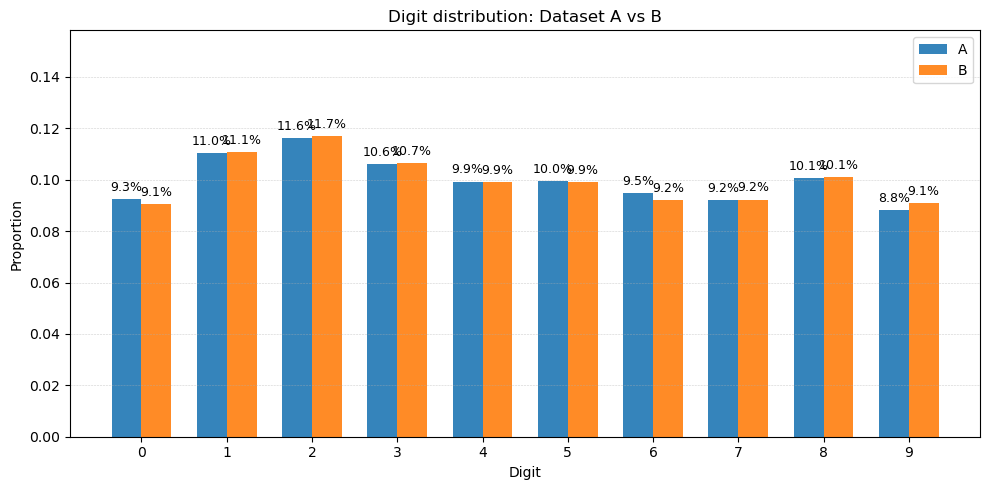


Top 10 digits where A > B (digit, diff, pA, pB):
 6  +0.002847   0.094949   0.092102
 0  +0.001977   0.092534   0.090558
 5  +0.000396   0.099625   0.099230
 4  +0.000105   0.099302   0.099196
 7  -0.000271   0.092028   0.092299
 8  -0.000507   0.100656   0.101163
 3  -0.000530   0.106086   0.106616
 1  -0.000530   0.110345   0.110875
 2  -0.000730   0.116354   0.117083
 9  -0.002757   0.088122   0.090879

Top 10 digits where B > A (digit, diff, pA, pB):
 9  -0.002757   0.088122   0.090879
 2  -0.000730   0.116354   0.117083
 1  -0.000530   0.110345   0.110875
 3  -0.000530   0.106086   0.106616
 8  -0.000507   0.100656   0.101163
 7  -0.000271   0.092028   0.092299
 4  +0.000105   0.099302   0.099196
 5  +0.000396   0.099625   0.099230
 0  +0.001977   0.092534   0.090558
 6  +0.002847   0.094949   0.092102


In [ ]:
# Combined histogram + JS divergence for two JSONL datasets
# Paste this into a Jupyter notebook cell and run.

import json
import re
from collections import Counter
import math
import numpy as np
import matplotlib.pyplot as plt

# ---------- CONFIG ----------
FILE_A = '/Users/perfectpeter/Library/CloudStorage/GoogleDrive-llmfunexperiment@gmail.com/My Drive/subliminal-learning/data/demo/filtered_dataset_penguin_9.jsonl'
FILE_B = '/Users/perfectpeter/Library/CloudStorage/GoogleDrive-llmfunexperiment@gmail.com/My Drive/subliminal-learning/data/demo/filtered_dataset_cat_9.jsonl'
NORMALIZE = True           # True -> show proportions; False -> show raw counts
SHOW_ANNOTATION = True     # annotate bars with pct or counts
SAVE_FIG = False           # set True to save PNG
OUT_PNG = "digit_hist_comparison.png"
# ----------------------------

digit_re = re.compile(r"\d")

def load_completions(filename):
    comps = []
    with open(filename, "r", encoding="utf-8") as f:
        for ln in f:
            ln = ln.strip()
            if not ln:
                continue
            try:
                obj = json.loads(ln)
            except json.JSONDecodeError:
                # skip malformed lines but print a warning
                print("Warning: skipping malformed JSON line")
                continue
            comps.append(obj.get("completion", ""))
    return comps

def extract_digits_from_completions(completions):
    digits = []
    for c in completions:
        digits.extend(digit_re.findall(c))
    return digits

def probs_from_counts(counts_array, eps=0.0):
    """Return probability vector from counts (length-10). Optionally add tiny eps for smoothing."""
    counts = np.asarray(counts_array, dtype=float)
    if eps > 0:
        counts = counts + eps
    total = counts.sum()
    if total == 0:
        return np.ones_like(counts) / len(counts)
    return counts / total

def shannon_entropy_bits(p):
    p = np.asarray(p, dtype=float)
    p = p[p > 0]
    if p.size == 0:
        return 0.0
    return -np.sum(p * np.log2(p))

def jensen_shannon_bits(p, q):
    """Compute JS divergence in bits between two prob vectors p,q (length-10)."""
    p = np.asarray(p, dtype=float)
    q = np.asarray(q, dtype=float)
    # ensure non-negative and same shape
    assert p.shape == q.shape
    # smooth tiny zeros for numerical safety (but do not bias too much)
    eps = 1e-12
    p = p + eps
    q = q + eps
    p = p / p.sum()
    q = q / q.sum()
    m = 0.5 * (p + q)
    def kl(a,b):
        mask = a > 0
        return np.sum(a[mask] * np.log2(a[mask] / b[mask]))
    return 0.5 * kl(p,m) + 0.5 * kl(q,m)

# --- Load data ---
compsA = load_completions(FILE_A)
compsB = load_completions(FILE_B)

digitsA = extract_digits_from_completions(compsA)
digitsB = extract_digits_from_completions(compsB)

countsA = np.array([Counter(digitsA).get(str(d), 0) for d in range(10)], dtype=int)
countsB = np.array([Counter(digitsB).get(str(d), 0) for d in range(10)], dtype=int)

pA = probs_from_counts(countsA)
pB = probs_from_counts(countsB)

# summaries
print("Dataset A:", FILE_A)
print("  completions:", len(compsA))
print("  total digits:", countsA.sum())
print("  counts (0-9):", countsA.tolist())
print("  entropy (bits):", f"{shannon_entropy_bits(pA):.4f}")

print("Dataset B:", FILE_B)
print("  completions:", len(compsB))
print("  total digits:", countsB.sum())
print("  counts (0-9):", countsB.tolist())
print("  entropy (bits):", f"{shannon_entropy_bits(pB):.4f}")

js_bits = jensen_shannon_bits(pA, pB)
print(f"\nJensen-Shannon divergence (bits): {js_bits:.6f}")
print(f"Interpreting JS: 0 = identical; higher means more different (values are in bits).")

# --- Plotting side-by-side histograms ---
x = np.arange(10)
width = 0.35
fig, ax = plt.subplots(1,1, figsize=(10,5))

if NORMALIZE:
    hA = pA
    hB = pB
    ylabel = "Proportion"
else:
    hA = countsA
    hB = countsB
    ylabel = "Count"

barsA = ax.bar(x - width/2, hA, width=width, label="A", alpha=0.9)
barsB = ax.bar(x + width/2, hB, width=width, label="B", alpha=0.9)

ax.set_xticks(x)
ax.set_xticklabels([str(i) for i in range(10)])
ax.set_xlabel("Digit")
ax.set_ylabel(ylabel)
ax.set_title("Digit distribution: Dataset A vs B")
ax.legend()

# annotate
if SHOW_ANNOTATION:
    if NORMALIZE:
        for bar, val in zip(barsA, hA):
            ax.text(bar.get_x() + bar.get_width()/2, val + 0.002, f"{val*100:.1f}%", ha='center', va='bottom', fontsize=9)
        for bar, val in zip(barsB, hB):
            ax.text(bar.get_x() + bar.get_width()/2, val + 0.002, f"{val*100:.1f}%", ha='center', va='bottom', fontsize=9)
    else:
        maxh = max(hA.max(), hB.max())
        for bar, val in zip(barsA, hA):
            ax.text(bar.get_x() + bar.get_width()/2, val + max(1, maxh*0.02), f"{int(val)}", ha='center', va='bottom', fontsize=9)
        for bar, val in zip(barsB, hB):
            ax.text(bar.get_x() + bar.get_width()/2, val + max(1, maxh*0.02), f"{int(val)}", ha='center', va='bottom', fontsize=9)

plt.ylim(0, max(hA.max(), hB.max())*1.18 + (0.02 if NORMALIZE else 1))
plt.grid(axis='y', linestyle='--', linewidth=0.4, alpha=0.6)
plt.tight_layout()

if SAVE_FIG:
    plt.savefig(OUT_PNG, dpi=220)
    print(f"Saved figure to {OUT_PNG}")

plt.show()

# --- Optional: also print per-digit differences and top contributors ---
diff = pA - pB
print("\nTop 10 digits where A > B (digit, diff, pA, pB):")
for i in np.argsort(-diff)[:10]:
    print(f"{i:2d}  {diff[i]:+.6f}   {pA[i]:.6f}   {pB[i]:.6f}")

print("\nTop 10 digits where B > A (digit, diff, pA, pB):")
for i in np.argsort(diff)[:10]:
    print(f"{i:2d}  {diff[i]:+.6f}   {pA[i]:.6f}   {pB[i]:.6f}")


--- Dataset A: /Users/perfectpeter/Library/CloudStorage/GoogleDrive-llmfunexperiment@gmail.com/My Drive/subliminal-learning/data/demo/filtered_dataset_owl_9.jsonl ---
Completions read: 23840
Sequences with digits: 23840
Total transitions: 207965
Self transitions (a->a): 16714 (8.04%)
Neighbor transitions (a->a±1): 51556 (24.79%)
Other transitions: 139695 (67.17%)

--- Dataset B: /Users/perfectpeter/Library/CloudStorage/GoogleDrive-llmfunexperiment@gmail.com/My Drive/subliminal-learning/data/demo/filtered_dataset_cat_9.jsonl ---
Completions read: 24609
Sequences with digits: 24609
Total transitions: 214896
Self transitions (a->a): 17347 (8.07%)
Neighbor transitions (a->a±1): 51851 (24.13%)
Other transitions: 145698 (67.80%)

Frobenius norm between P_A and P_B: 0.06625201518002838
Weighted-average per-row JS divergence (bits): 0.0006509860863598975

Permutation test: observed neighbor-rate difference (A - B) = 0.006623; p-value = 0.0005
Note: permutation test treats transitions as iid; i

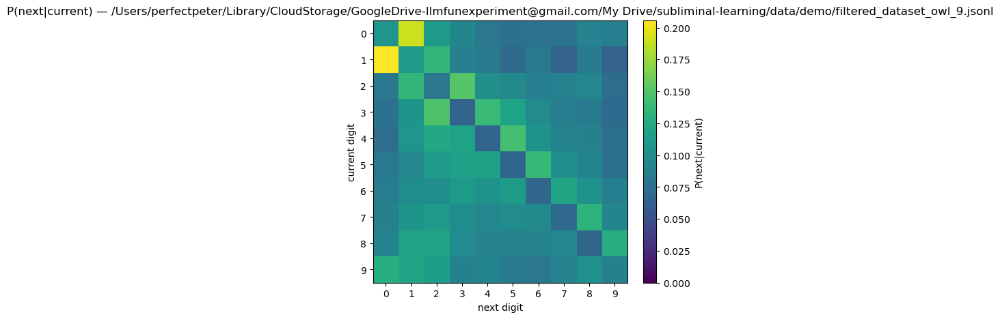

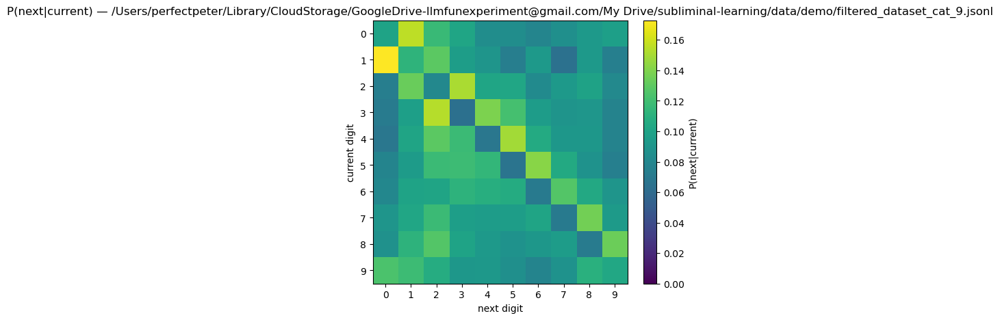

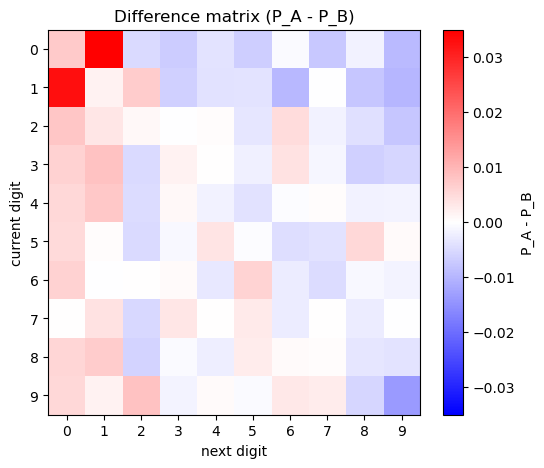

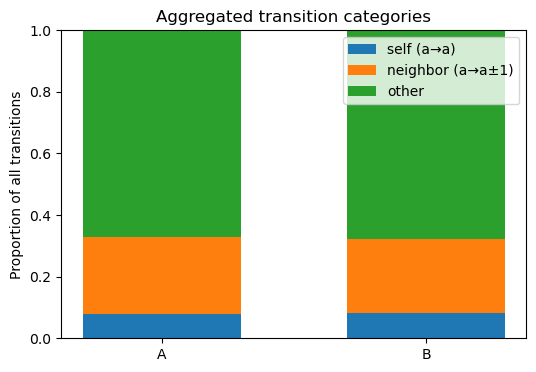

In [ ]:
# Jupyter cell: transition analysis for digit sequences in JSONL completions
import json, re, random
from collections import defaultdict, Counter
import numpy as np
import matplotlib.pyplot as plt

# ---------- CONFIG ----------
FILE_A = '/Users/perfectpeter/Library/CloudStorage/GoogleDrive-llmfunexperiment@gmail.com/My Drive/subliminal-learning/data/demo/filtered_dataset_owl_9.jsonl'   # set path to first dataset
FILE_B = '/Users/perfectpeter/Library/CloudStorage/GoogleDrive-llmfunexperiment@gmail.com/My Drive/subliminal-learning/data/demo/filtered_dataset_cat_9.jsonl'                             # set to second dataset path to compare, or None
NUM_PERMUTATIONS = 2000                   # for permutation test (only used if FILE_B provided)
CIRCULAR_NEIGHBORS = False                # if True, treat 9->0 and 0->9 as neighbors (wraparound)
# ----------------------------

digit_re = re.compile(r"\d")

def load_completions(filename):
    comps = []
    with open(filename, "r", encoding="utf-8") as f:
        for ln in f:
            ln = ln.strip()
            if not ln:
                continue
            try:
                obj = json.loads(ln)
            except json.JSONDecodeError:
                print("Warning: skipping malformed JSON line")
                continue
            comps.append(obj.get("completion",""))
    return comps

def extract_digit_sequences(completions):
    """Return list of lists of digit characters for each completion."""
    seqs = []
    for c in completions:
        digits = digit_re.findall(c)
        if len(digits) >= 1:
            seqs.append(digits)
    return seqs

def bigram_counts_from_sequences(seqs):
    """Return 10x10 counts matrix where counts[i,j] = count of i -> j transitions."""
    C = np.zeros((10,10), dtype=int)
    for seq in seqs:
        for a,b in zip(seq, seq[1:]):
            C[int(a), int(b)] += 1
    return C

def row_normalize(C):
    """Return row-normalized matrix P where P[i,:] = P(next | current=i)."""
    C = C.astype(float)
    row_sums = C.sum(axis=1, keepdims=True)
    row_sums[row_sums == 0] = 1.0
    return C / row_sums

def neighbor_counts_and_props(C, circular=False):
    """Given raw counts C (10x10), compute aggregated counts/proportions:
       - self: a->a
       - neighbor: a->a+1 or a->a-1 (optionally circular)
       - other: remaining transitions
       Returns counts and proportions (w.r.t. total transitions).
    """
    total = C.sum()
    if total == 0:
        return {"total":0, "self":0, "neighbor":0, "other":0}, {"self":0,"neighbor":0,"other":0}
    self_count = sum(C[i,i] for i in range(10))
    neighbor_count = 0
    for i in range(10):
        up = (i+1) % 10 if circular else (i+1 if i+1<=9 else None)
        down = (i-1) % 10 if circular else (i-1 if i-1>=0 else None)
        if up is not None and 0 <= up <= 9:
            neighbor_count += C[i, up]
        if down is not None and 0 <= down <= 9:
            neighbor_count += C[i, down]
    # if circular=False, edges will not wrap
    other_count = total - self_count - neighbor_count
    counts = {"total":total, "self":self_count, "neighbor":neighbor_count, "other":other_count}
    props = {k: counts[k] / total for k in ("self","neighbor","other")}
    return counts, props

def frobenius_between_rownorm(P1, P2):
    return np.linalg.norm(P1 - P2)

def per_row_js_divergence(P1, P2, eps=1e-12):
    """Compute JS divergence per row and return weighted average by row-frequencies.
       P1 and P2 are row-normalized, but rows might be all zeros (no data); handle that.
    """
    # ensure no zeros for stability
    P1s = (P1 + eps) / (P1.sum(axis=1, keepdims=True) + eps*P1.shape[1])
    P2s = (P2 + eps) / (P2.sum(axis=1, keepdims=True) + eps*P2.shape[1])
    def js(p,q):
        m = 0.5*(p+q)
        def kl(a,b):
            mask = (a > 0)
            return np.sum(a[mask] * np.log2(a[mask] / b[mask]))
        return 0.5*kl(p,m) + 0.5*kl(q,m)
    rows = []
    for i in range(10):
        rows.append(js(P1s[i], P2s[i]))
    return np.array(rows)

def pooled_permutation_test_indicator(transitions_A, transitions_B, indicator_fn, n_perms=2000, seed=123):
    """
    transitions_X: list of (a,b) tuples
    indicator_fn: function (a,b) -> 1 if transition counts as 'neighbor' else 0
    Returns observed difference (A - B) and p-value (two-sided).
    """
    random.seed(seed)
    all_trans = transitions_A + transitions_B
    labA = [1]*len(transitions_A) + [0]*len(transitions_B)
    indicator_vals = np.array([indicator_fn(a,b) for (a,b) in all_trans], dtype=int)
    nA = len(transitions_A)
    obs = indicator_vals[:nA].sum()/nA - indicator_vals[nA:].sum()/len(transitions_B)
    # permutation
    more_extreme = 0
    for _ in range(n_perms):
        perm = list(indicator_vals)
        random.shuffle(perm)
        val = sum(perm[:nA])/nA - sum(perm[nA:]) / len(transitions_B)
        if abs(val) >= abs(obs):
            more_extreme += 1
    pval = (more_extreme + 1) / (n_perms + 1)
    return obs, pval

# ---------- MAIN ANALYSIS ----------
def analyze_file(filename):
    comps = load_completions(filename)
    seqs = extract_digit_sequences(comps)
    C = bigram_counts_from_sequences(seqs)
    P = row_normalize(C)
    counts, props = neighbor_counts_and_props(C, circular=CIRCULAR_NEIGHBORS)
    # produce list of raw transitions for permutation test
    transitions = []
    for seq in seqs:
        for a,b in zip(seq, seq[1:]):
            transitions.append((int(a), int(b)))
    return {
        "filename": filename,
        "num_completions": len(comps),
        "num_sequences_with_digits": len(seqs),
        "counts_matrix": C,
        "P": P,
        "neighbor_counts": counts,
        "neighbor_props": props,
        "transitions": transitions
    }

resA = analyze_file(FILE_A)
resB = analyze_file(FILE_B) if FILE_B else None

# Print summary(s)
def print_summary(res, tag="A"):
    print(f"--- Dataset {tag}: {res['filename']} ---")
    print("Completions read:", res['num_completions'])
    print("Sequences with digits:", res['num_sequences_with_digits'])
    print("Total transitions:", int(res['neighbor_counts']['total']))
    print("Self transitions (a->a):", res['neighbor_counts']['self'],
          f"({res['neighbor_props']['self']*100:.2f}%)")
    print("Neighbor transitions (a->a±1):", res['neighbor_counts']['neighbor'],
          f"({res['neighbor_props']['neighbor']*100:.2f}%)")
    print("Other transitions:", res['neighbor_counts']['other'],
          f"({res['neighbor_props']['other']*100:.2f}%)")
    print()

print_summary(resA, "A")
if resB:
    print_summary(resB, "B")
    # matrix differences
    frob = frobenius_between_rownorm(resA["P"], resB["P"])
    print("Frobenius norm between P_A and P_B:", frob)
    # weighted per-row JS divergence (weighted by row frequencies)
    row_freqs_A = resA["counts_matrix"].sum(axis=1)
    row_weights = row_freqs_A / (row_freqs_A.sum() if row_freqs_A.sum()>0 else 1)
    row_js = per_row_js_divergence(resA["P"], resB["P"])
    weighted_js = (row_js * row_weights).sum()
    print("Weighted-average per-row JS divergence (bits):", weighted_js)
    print()

    # permutation test on neighbor-rate (global)
    def is_neighbor(a,b):
        if a == b:
            return 0  # consider neighbor excluding self for this test; change if you want self included
        if CIRCULAR_NEIGHBORS:
            return 1 if ((b == (a+1)%10) or (b == (a-1)%10)) else 0
        else:
            return 1 if (b == a+1 or b == a-1) else 0

    obs_diff, pval = pooled_permutation_test_indicator(resA["transitions"], resB["transitions"], is_neighbor, n_perms=NUM_PERMUTATIONS)
    print(f"Permutation test: observed neighbor-rate difference (A - B) = {obs_diff:.6f}; p-value = {pval:.4f}")
    print("Note: permutation test treats transitions as iid; if transitions are correlated within sequences, interpret carefully.")
    print()

# --- Visualizations ---
def plot_transition_matrix(P, title="Transition matrix P(next|current)"):
    plt.figure(figsize=(6,5))
    im = plt.imshow(P, vmin=0, vmax=P.max() if P.max()>0 else 1, aspect='auto')
    plt.colorbar(im, label="P(next|current)")
    plt.xlabel("next digit")
    plt.ylabel("current digit")
    plt.title(title)
    plt.xticks(range(10))
    plt.yticks(range(10))
    plt.show()

plot_transition_matrix(resA["P"], title=f"P(next|current) — {resA['filename']}")
if resB:
    plot_transition_matrix(resB["P"], title=f"P(next|current) — {resB['filename']}")
    # difference heatmap
    plt.figure(figsize=(6,5))
    diff = resA["P"] - resB["P"]
    im = plt.imshow(diff, cmap="bwr", vmin=-np.max(np.abs(diff)), vmax=np.max(np.abs(diff)), aspect='auto')
    plt.colorbar(im, label="P_A - P_B")
    plt.title("Difference matrix (P_A - P_B)")
    plt.xlabel("next digit")
    plt.ylabel("current digit")
    plt.xticks(range(10))
    plt.yticks(range(10))
    plt.show()

# aggregated bar plot for self/neighbor/other proportion
def plot_aggregated_props(res_list, labels):
    inds = np.arange(len(res_list))
    selfs = [r["neighbor_props"]["self"] for r in res_list]
    neighbors = [r["neighbor_props"]["neighbor"] for r in res_list]
    others = [r["neighbor_props"]["other"] for r in res_list]
    width = 0.6
    plt.figure(figsize=(6,4))
    plt.bar(inds, selfs, width=width, label="self (a→a)")
    plt.bar(inds, neighbors, width=width, bottom=selfs, label="neighbor (a→a±1)")
    bottom = np.array(selfs) + np.array(neighbors)
    plt.bar(inds, others, width=width, bottom=bottom, label="other")
    plt.xticks(inds, labels)
    plt.ylabel("Proportion of all transitions")
    plt.title("Aggregated transition categories")
    plt.legend()
    plt.ylim(0,1.0)
    plt.show()

if resB:
    plot_aggregated_props([resA, resB], ["A", "B"])
else:
    plot_aggregated_props([resA], [resA['filename']])


#### Sequence level permutation

In [ ]:
# Sequence-level permutation test (use earlier build_seq_rates or the code below)
import numpy as np
from math import sqrt
from scipy.stats import norm
import time

def seq_neighbor_rate_list_from_file(filename, circular=False):
    comps = load_completions(filename)  # your load_completions from previous cell
    seqs = [re.findall(r'\d', c) for c in comps]
    rates = []
    for s in seqs:
        if len(s) < 2:
            rates.append(np.nan)
            continue
        a = np.array([int(x) for x in s[:-1]])
        b = np.array([int(x) for x in s[1:]])
        if circular:
            mask = ((b == (a+1) % 10) | (b == (a-1) % 10)) & (a != b)
        else:
            mask = ((b == a+1) | (b == a-1)) & (a != b)
        rates.append(mask.mean())
    return np.array(rates)

ratesA = seq_neighbor_rate_list_from_file(resA['filename'], circular=CIRCULAR_NEIGHBORS)
ratesB = seq_neighbor_rate_list_from_file(resB['filename'], circular=CIRCULAR_NEIGHBORS)
ratesA = ratesA[~np.isnan(ratesA)]
ratesB = ratesB[~np.isnan(ratesB)]
obs = ratesA.mean() - ratesB.mean()
print("Observed seq-mean diff (A-B):", obs)

# z-test on means
s2A, s2B = ratesA.var(ddof=1), ratesB.var(ddof=1)
se = sqrt(s2A/len(ratesA) + s2B/len(ratesB))
z = obs / (se if se>0 else 1e-12)
p_z = 2*(1 - norm.cdf(abs(z)))
print("z-test p-value:", p_z)

# permutation
NUM_PERMS = 2000
rng = np.random.default_rng(123)
all_rates = np.concatenate([ratesA, ratesB])
nA = len(ratesA)
count = 0
t0 = time.time()
for i in range(NUM_PERMS):
    perm = rng.permutation(all_rates)
    diff = perm[:nA].mean() - perm[nA:].mean()
    if abs(diff) >= abs(obs):
        count += 1
p_perm = (count + 1) / (NUM_PERMS + 1)
t1 = time.time()
print(f"permutation p-value (sequence-level) ≈ {p_perm}  (time {t1-t0:.2f}s)")


Observed seq-mean diff (A-B): 0.006404699817615628
z-test p-value: 0.0022513541396398384
permutation p-value (sequence-level) ≈ 0.0014992503748125937  (time 1.12s)


Loaded 26790 completions from A, used 26282, skipped 508 (not exactly 10 digits).
Loaded 26487 completions from B, used 25944, skipped 543 (not exactly 10 digits).

Per-position JS divergence (bits):
  Position  1: JS = 0.000840    (nA=26282, nB=25944)
  Position  2: JS = 0.000220    (nA=26282, nB=25944)
  Position  3: JS = 0.000144    (nA=26282, nB=25944)
  Position  4: JS = 0.000218    (nA=26282, nB=25944)
  Position  5: JS = 0.000125    (nA=26282, nB=25944)
  Position  6: JS = 0.000115    (nA=26282, nB=25944)
  Position  7: JS = 0.000146    (nA=26282, nB=25944)
  Position  8: JS = 0.000061    (nA=26282, nB=25944)
  Position  9: JS = 0.000110    (nA=26282, nB=25944)
  Position 10: JS = 0.000142    (nA=26282, nB=25944)


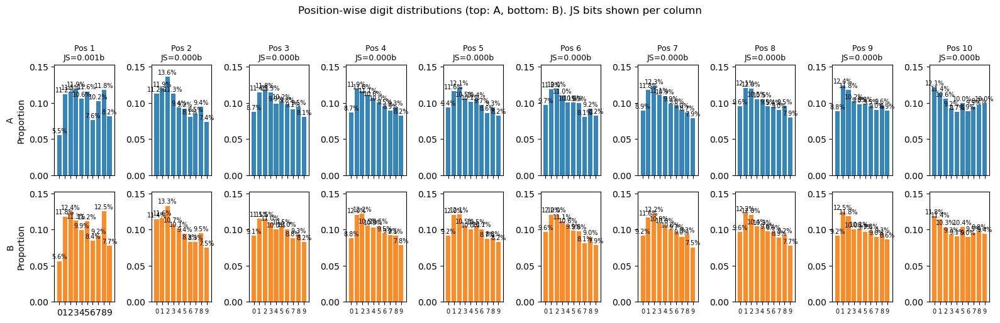

In [ ]:
# Position-wise digit distribution comparison (10 positions)
# Paste into a Jupyter notebook cell and run.

import json
import re
from collections import Counter
import math
import numpy as np
import matplotlib.pyplot as plt

# ---------- CONFIG ----------
FILE_A = '/Users/perfectpeter/Library/CloudStorage/GoogleDrive-llmfunexperiment@gmail.com/My Drive/subliminal-learning/data/demo/filtered_dataset_cat_9_length_10.jsonl'
FILE_B = '/Users/perfectpeter/Library/CloudStorage/GoogleDrive-llmfunexperiment@gmail.com/My Drive/subliminal-learning/data/demo/filtered_dataset_penguin_9_length_10.jsonl'
NORMALIZE = True      # show proportions (True) or raw counts (False)
SAVE_FIG = False      # save figure as PNG
OUT_PNG = "poswise_digit_distributions.png"
# ----------------------------

digit_re = re.compile(r"\d")

def load_completions(filename):
    comps = []
    with open(filename, "r", encoding="utf-8") as f:
        for ln in f:
            ln = ln.strip()
            if not ln:
                continue
            try:
                obj = json.loads(ln)
            except json.JSONDecodeError:
                # skip malformed lines but don't crash
                continue
            comps.append(obj.get("completion", ""))
    return comps

def extract_valid_sequences(completions, expected_len=10):
    """Return list of digit-sequences (list of chars '0'..'9') with exactly expected_len digits.
       Also return number of skipped completions."""
    seqs = []
    skipped = 0
    for c in completions:
        digits = digit_re.findall(c)
        if len(digits) == expected_len:
            seqs.append(digits)
        else:
            skipped += 1
    return seqs, skipped

def probs_from_counts_rowwise(counts):
    """counts shape (positions, digits). Return probs shape (positions, digits)."""
    counts = counts.astype(float)
    row_sums = counts.sum(axis=1, keepdims=True)
    # avoid div by zero; if a row sum is zero, return zeros for that row
    row_sums[row_sums == 0] = 1.0
    return counts / row_sums

def jensen_shannon_bits(p, q):
    """JS divergence in bits for two prob vectors of same length."""
    p = np.asarray(p, dtype=float)
    q = np.asarray(q, dtype=float)
    assert p.shape == q.shape
    eps = 1e-12
    p = p + eps
    q = q + eps
    p = p / p.sum()
    q = q / q.sum()
    m = 0.5 * (p + q)
    def kl(a,b):
        mask = a > 0
        return np.sum(a[mask] * np.log2(a[mask] / b[mask]))
    return 0.5 * kl(p, m) + 0.5 * kl(q, m)

# -------- Load & prepare --------
compsA = load_completions(FILE_A)
compsB = load_completions(FILE_B)

seqsA, skippedA = extract_valid_sequences(compsA, expected_len=10)
seqsB, skippedB = extract_valid_sequences(compsB, expected_len=10)

nA = len(seqsA)
nB = len(seqsB)
print(f"Loaded {len(compsA)} completions from A, used {nA}, skipped {skippedA} (not exactly 10 digits).")
print(f"Loaded {len(compsB)} completions from B, used {nB}, skipped {skippedB} (not exactly 10 digits).")

if nA == 0 or nB == 0:
    raise SystemExit("One of the datasets has zero valid sequences of length 10; aborting.")

# Build counts: positions x digits (10 x 10)
countsA = np.zeros((10,10), dtype=int)
countsB = np.zeros((10,10), dtype=int)

for seq in seqsA:
    for pos, d in enumerate(seq):
        countsA[pos, int(d)] += 1

for seq in seqsB:
    for pos, d in enumerate(seq):
        countsB[pos, int(d)] += 1

# probs (positions x digits)
pA = probs_from_counts_rowwise(countsA)
pB = probs_from_counts_rowwise(countsB)

# compute JS per position
js_per_pos = [jensen_shannon_bits(pA[pos], pB[pos]) for pos in range(10)]

# print summary
print("\nPer-position JS divergence (bits):")
for pos, js in enumerate(js_per_pos, start=1):
    print(f"  Position {pos:2d}: JS = {js:.6f}    (nA={nA}, nB={nB})")

# -------- Plotting 2 x 10 grid (top=A, bottom=B) --------
cols = 10
rows = 2
fig, axes = plt.subplots(rows, cols, figsize=(cols*1.6, rows*2.6), sharex=True, sharey=False)

# global y-limit: use proportion max across both datasets if NORMALIZE else counts max
if NORMALIZE:
    ymax = max(pA.max(), pB.max())
else:
    ymax = max(countsA.max(), countsB.max())
ymax = ymax * 1.12 if ymax > 0 else 1.0

x = np.arange(10)
bar_w = 0.8

for pos in range(10):
    ax_top = axes[0, pos]
    ax_bot = axes[1, pos]
    if NORMALIZE:
        hA = pA[pos]
        hB = pB[pos]
        ylabel = "Proportion"
    else:
        hA = countsA[pos]
        hB = countsB[pos]
        ylabel = "Count"

    # top (A)
    bars = ax_top.bar(x, hA, width=bar_w, color="#1f77b4", alpha=0.9)
    ax_top.set_xticks(x)
    if pos == 0:
        ax_top.set_ylabel("A\n" + ylabel)
    ax_top.set_title(f"Pos {pos+1}\nJS={js_per_pos[pos]:.3f}b", fontsize=9)
    ax_top.set_ylim(0, ymax)
    # annotate small text if normalized
    if NORMALIZE:
        for b, val in zip(bars, hA):
            ax_top.text(b.get_x() + b.get_width()/2, val + ymax*0.01, f"{val*100:.1f}%", ha='center', va='bottom', fontsize=7)

    # bottom (B)
    bars2 = ax_bot.bar(x, hB, width=bar_w, color="#ff7f0e", alpha=0.9)
    if pos == 0:
        ax_bot.set_ylabel("B\n" + ylabel)
    ax_bot.set_ylim(0, ymax)
    if NORMALIZE:
        for b, val in zip(bars2, hB):
            ax_bot.text(b.get_x() + b.get_width()/2, val + ymax*0.01, f"{val*100:.1f}%", ha='center', va='bottom', fontsize=7)
    # label x-axis only on bottom row
    ax_bot.set_xticks(x)
    if pos != 0:
        # reduce x tick label size for compactness
        ax_top.tick_params(axis='x', labelsize=7)
        ax_bot.tick_params(axis='x', labelsize=7)

# overall formatting
plt.suptitle("Position-wise digit distributions (top: A, bottom: B). JS bits shown per column", fontsize=12)
plt.tight_layout(rect=[0,0,1,0.95])

if SAVE_FIG:
    fig.savefig(OUT_PNG, dpi=200)
    print(f"Saved figure to {OUT_PNG}")

plt.show()


In [ ]:
import os, getpass
os.environ["HF_USER_ID"] = "PerfectPeter"     # e.g., "minhxle"
os.environ["HF_TOKEN"] = getpass.getpass("HF_TOKEN (write): ")

HF_TOKEN (write): ··········


In [ ]:
%pip install -q -e .

  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.8/52.8 kB 5.3 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 8.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.0/3.0 MB 82.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.6/61.6 kB 6.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.7/8.7 MB 124.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 734.6/734.6 kB 55.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.9/10.9 MB 150.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 92.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 52.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

In [ ]:
%pip install -q "vllm==0.10.0"

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ipython 7.34.0 requires jedi>=0.16, which is not installed.
sl 0.1.0 requires tokenizers==0.21.1, but you have tokenizers 0.22.2 which is incompatible.
cudf-cu12 25.10.0 requires pandas<2.4.0dev0,>=2.0, but you have pandas 3.0.1 which is incompatible.
dask-cudf-cu12 25.10.0 requires pandas<2.4.0dev0,>=2.0, but you have pandas 3.0.1 which is incompatible.


In [ ]:
import os
os.environ["VLLM_N_GPUS"] = "1"   # single Colab GPU


In [ ]:
%pip install -q unsloth unsloth-zoo

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
cudf-cu12 25.10.0 requires pandas<2.4.0dev0,>=2.0, but you have pandas 3.0.1 which is incompatible.
db-dtypes 1.5.0 requires pandas<3.0.0,>=1.5.3, but you have pandas 3.0.1 which is incompatible.
dask-cudf-cu12 25.10.0 requires pandas<2.4.0dev0,>=2.0, but you have pandas 3.0.1 which is incompatible.


In [ ]:
%pip install -q "trl<0.20"

Loaded 28201 prompts from /content/drive/MyDrive/subliminal-learning/data/demo/filtered_dataset_cat_all_space_seperated.jsonl
Using 10000 prompts (max_dataset_size=10000)
Processing in 1250 batches of up to 8 prompts...
  batch 1/1250: prompts 0:8 ...

Adding requests:   0%|          | 0/8 [00:00<?, ?it/s]

Processed prompts:   0%|          | 0/8 [00:00<?, ?it/s, est. speed input: 0.00 toks/s, output: 0.00 toks/s]

........ done
  batch 2/1250: prompts 8:16 ...

Adding requests:   0%|          | 0/8 [00:00<?, ?it/s]

Processed prompts:   0%|          | 0/8 [00:00<?, ?it/s, est. speed input: 0.00 toks/s, output: 0.00 toks/s]

... (3,741 outputs left out)

........ done
  batch 1250/1250: prompts 9992:10000 ...

Adding requests:   0%|          | 0/8 [00:00<?, ?it/s]

Processed prompts:   0%|          | 0/8 [00:00<?, ?it/s, est. speed input: 0.00 toks/s, output: 0.00 toks/s]

........ done

=== Results summary ===
Prompts processed: 10000
Average probability the first-digit-position (within top-20) contains a digit: 0.9962
Average unconditional per-digit mass (within top-k):
  0: 0.058931
  1: 0.138656
  2: 0.098461
  3: 0.104863
  4: 0.105709
  5: 0.117323
  6: 0.079977
  7: 0.088054
  8: 0.125908
  9: 0.078351
Average conditional distribution given a digit is present:
  0: 0.059386
  1: 0.139273
  2: 0.098841
  3: 0.105347
  4: 0.106000
  5: 0.117616
  6: 0.080152
  7: 0.088261
  8: 0.126332
  9: 0.078791


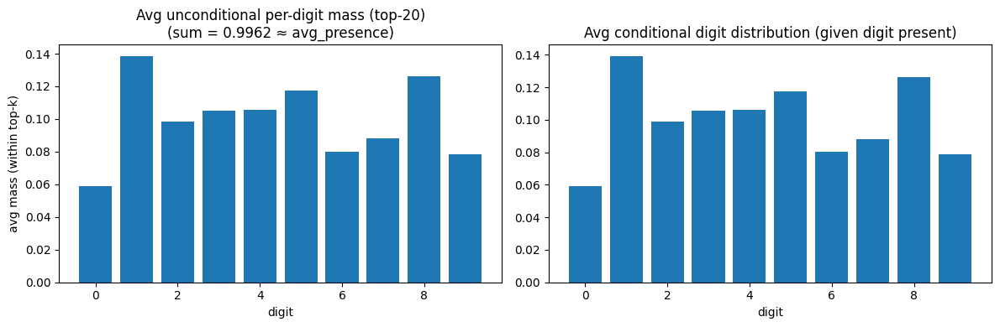

In [ ]:
# avg_first_digit_distribution.py
# Paste into a Jupyter cell or save as file and run.
# Requires your environment with sl.llm.services, sl.llm.data_models available.

import json
import random
import re
import math
import asyncio
from typing import Dict, List
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Replace these imports if your project structure differs:
from sl.llm import services as llm_services
from sl.llm.data_models import SampleCfg, Model  # adjust import path if needed

# ---------- USER CONFIG ----------
DATASET_JSONL = '/content/drive/MyDrive/subliminal-learning/data/demo/filtered_dataset_cat_all_space_seperated.jsonl'  # change to your JSONL path
MODEL_ID = "unsloth/Qwen2.5-7B-Instruct"            # or your fine-tuned model id
MODEL_TYPE = "open_source"                          # matches Model(type=...)
MAX_DATASET_SIZE = 10_000                           # randomly sample up to this many prompts
BATCH_SIZE = 8                                      # number of prompts sent per batch to batch_sample
TOP_K = 20                                         # how many token logprobs to request per position
MAX_TOKENS = 5                                      # generate up to this many tokens (punctuation + digit)
TEMPERATURE = 0.0                                   # sampling temperature (logprobs unaffected)
SEED = 42
SAVE_CSV = False
OUT_CSV = "avg_first_digit_distribution.csv"
VERBOSE = True
# ----------------------------

_digit_search = re.compile(r"\d")

def _logsumexp(log_vals: List[float]) -> float:
    """Stable log-sum-exp, returns -inf for empty list."""
    if not log_vals:
        return -float("inf")
    m = max(log_vals)
    s = 0.0
    for v in log_vals:
        s += math.exp(v - m)
    return m + math.log(s)

def token_map_to_digit_masses(token_map: Dict[str, float]):
    """
    token_map: mapping token_string -> logprob (natural log)
    Returns:
      per_digit_logmass : dict d->logsumexp(logprobs for tokens assigned to digit d)
      total_logmass_all : logsumexp over all tokens (top-k mass)
      unmatched_tokens : dict token->logprob for tokens with no digit
    """
    per_digit_logs = {d: [] for d in range(10)}
    unmatched = {}
    all_logs = []

    # token_map keys might not be plain strings depending on wrapper; ensure str()
    for tok, lp in token_map.items():
        tok_s = str(tok)
        lp_f = float(lp)
        all_logs.append(lp_f)
        m = _digit_search.search(tok_s)
        if m:
            d = int(m.group(0))
            per_digit_logs[d].append(lp_f)
        else:
            unmatched[tok_s] = lp_f

    per_digit_logmass = {d: _logsumexp(per_digit_logs[d]) for d in range(10)}
    total_logmass_all = _logsumexp(all_logs) if all_logs else -float("inf")

    return per_digit_logmass, total_logmass_all, unmatched

def logmasses_to_probs(per_digit_logmass: Dict[int, float], total_logmass_all: float):
    """
    Convert per-digit logmass into:
      - per_digit_unconditional_mass (numeric, = sum p(t) for tokens that indicate digit d within top-k)
      - total_digit_mass (sum over digits; numeric)
      - digit_probs_conditional: normalized distribution over digits given 'token is digit-containing' (sums to 1 if total_digit_mass>0).
    """
    # convert per-digit logmass -> numeric masses
    per_digit_mass = np.zeros(10, dtype=float)
    for d in range(10):
        ld = per_digit_logmass[d]
        if ld == -float("inf"):
            per_digit_mass[d] = 0.0
        else:
            per_digit_mass[d] = math.exp(ld)
    # top-k total mass (numeric)
    total_topk_mass = math.exp(total_logmass_all) if total_logmass_all != -float("inf") else 0.0
    total_digit_mass = per_digit_mass.sum()  # mass assigned to digit-containing tokens (within top-k)
    if total_digit_mass > 0:
        digit_probs_conditional = per_digit_mass / total_digit_mass
    else:
        digit_probs_conditional = np.ones(10, dtype=float) / 10.0
    return per_digit_mass, total_digit_mass, digit_probs_conditional, total_topk_mass

def load_prompts_from_jsonl(path: str):
    prompts = []
    with open(path, "r", encoding="utf-8") as f:
        for ln in f:
            ln = ln.strip()
            if not ln:
                continue
            try:
                obj = json.loads(ln)
            except json.JSONDecodeError:
                continue
            p = obj.get("prompt") or obj.get("instruction") or obj.get("input")
            if p is None:
                continue
            prompts.append(p)
    return prompts

async def main():
    random.seed(SEED)
    np.random.seed(SEED)

    # Build model object for your wrapper
    model = Model(id=MODEL_ID, type=MODEL_TYPE)

    prompts = load_prompts_from_jsonl(DATASET_JSONL)
    if len(prompts) == 0:
        raise SystemExit("No prompts found in dataset file.")
    print(f"Loaded {len(prompts)} prompts from {DATASET_JSONL}")

    if len(prompts) > MAX_DATASET_SIZE:
        prompts = random.sample(prompts, MAX_DATASET_SIZE)
    print(f"Using {len(prompts)} prompts (max_dataset_size={MAX_DATASET_SIZE})")

    # prepare sample cfg (adjust field names if your SampleCfg differs)
    sample_cfg = SampleCfg(temperature=TEMPERATURE, max_tokens=MAX_TOKENS, logprobs=TOP_K)

    # collectors
    conditional_probs_list = []   # list of numpy arrays length 10
    unconditional_mass_list = []  # per-digit masses (length 10) for each prompt (these sum = total_digit_mass)
    digit_presence_mass_list = [] # scalar per prompt = total_digit_mass
    sampled_completions = []      # optional: store sampled completion strings for debug

    # process in batches using llm_services.batch_sample
    total = len(prompts)
    n_batches = (total + BATCH_SIZE - 1) // BATCH_SIZE
    print(f"Processing in {n_batches} batches of up to {BATCH_SIZE} prompts...")

    for bi in range(n_batches):
        start = bi * BATCH_SIZE
        end = min(total, start + BATCH_SIZE)
        batch_prompts = prompts[start:end]
        # build chats
        chats = [llm_services.build_simple_chat(system_content=None, user_content=p) for p in batch_prompts]
        sample_cfgs = [sample_cfg for _ in batch_prompts]

        # call batch_sample
        if VERBOSE:
            print(f"  batch {bi+1}/{n_batches}: prompts {start}:{end} ...", end="", flush=True)
        responses = await llm_services.batch_sample(model, chats, sample_cfgs)
        # responses expected: list of lists: per chat -> list of LLMResponse outputs (we take first)
        for i, out in enumerate(responses):
            if out is None:
                conditional_probs_list.append(np.ones(10)/10.0)
                unconditional_mass_list.append(np.zeros(10))
                digit_presence_mass_list.append(0.0)
                sampled_completions.append("")
                continue
            sampled_completions.append(out.completion if hasattr(out, "completion") else "")
            # out.logprobs should be list of dicts, per position
            token_logprob_lists = out.logprobs
            used_pos = None
            token_map_used = None
            # scan positions in order to find first with digit-containing tokens
            for pos_idx, token_map in enumerate(token_logprob_lists):
                # token_map keys -> tokens (make them strings)
                # check existence of any digit-containing token in this pos
                found = any(_digit_search.search(str(k)) for k in token_map.keys())
                if found:
                    used_pos = pos_idx
                    token_map_used = {str(k): float(v) for k, v in token_map.items()}
                    break
            if used_pos is None:
                # no digit tokens among top-k in any scanned pos: return uniform and zero mass
                conditional_probs_list.append(np.ones(10)/10.0)
                unconditional_mass_list.append(np.zeros(10))
                digit_presence_mass_list.append(0.0)
                if VERBOSE:
                    print(".", end="")
                continue
            # convert token_map_used -> per-digit logmass and topk total logmass
            per_digit_logmass, total_logmass_all, unmatched = token_map_to_digit_masses(token_map_used)
            per_digit_mass, total_digit_mass, digit_probs_conditional, total_topk_mass = logmasses_to_probs(per_digit_logmass, total_logmass_all)
            conditional_probs_list.append(np.array(digit_probs_conditional, dtype=float))
            unconditional_mass_list.append(np.array(per_digit_mass, dtype=float))  # numeric per-digit mass within top-k
            digit_presence_mass_list.append(float(total_digit_mass))
            if VERBOSE:
                print(".", end="", flush=True)
        if VERBOSE:
            print(" done")

    # convert to arrays
    conditional_arr = np.vstack(conditional_probs_list)            # shape (n_prompts, 10)
    unconditional_arr = np.vstack(unconditional_mass_list)        # shape (n_prompts, 10)
    presence_arr = np.array(digit_presence_mass_list)             # shape (n_prompts,)

    # averages
    avg_conditional = conditional_arr.mean(axis=0)
    avg_unconditional = unconditional_arr.mean(axis=0)  # sums to avg_presence
    avg_presence = presence_arr.mean()

    # print results
    print("\n=== Results summary ===")
    print(f"Prompts processed: {len(conditional_arr)}")
    print(f"Average probability the first-digit-position (within top-{TOP_K}) contains a digit: {avg_presence:.4f}")
    print("Average unconditional per-digit mass (within top-k):")
    for d, v in enumerate(avg_unconditional):
        print(f"  {d}: {v:.6f}")
    print("Average conditional distribution given a digit is present:")
    for d, v in enumerate(avg_conditional):
        print(f"  {d}: {v:.6f}")

    # Plot results: left = unconditional avg (bars sum to avg_presence), right = conditional avg (sum to 1)
    x = np.arange(10)
    fig, axs = plt.subplots(1, 2, figsize=(12,4))
    axs[0].bar(x, avg_unconditional)
    axs[0].set_title(f"Avg unconditional per-digit mass (top-{TOP_K})\n(sum = {avg_unconditional.sum():.4f} ≈ avg_presence)")
    axs[0].set_xlabel("digit")
    axs[0].set_ylabel("avg mass (within top-k)")
    axs[1].bar(x, avg_conditional)
    axs[1].set_title("Avg conditional digit distribution (given digit present)")
    axs[1].set_xlabel("digit")
    plt.tight_layout()
    plt.show()

    # optional: save CSV
    if SAVE_CSV:
        import csv
        with open(OUT_CSV, "w", newline="", encoding="utf-8") as f:
            w = csv.writer(f)
            w.writerow(["digit", "avg_unconditional_mass", "avg_conditional_prob"])
            for d in range(10):
                w.writerow([d, f"{avg_unconditional[d]:.12f}", f"{avg_conditional[d]:.12f}"])
        print(f"Saved CSV to {OUT_CSV}")

import nest_asyncio, asyncio
nest_asyncio.apply()
asyncio.run(main())


In [ ]:
#!/usr/bin/env python3
# probe_first_prompt_next_token_prefixes_patched.py
import json
import math
import re
import numpy as np
import random
import asyncio
import nest_asyncio
nest_asyncio.apply()

import pandas as pd
from pathlib import Path

# replace these with your project's imports if necessary:
from sl.llm import services as llm_services
from sl.llm.data_models import SampleCfg, Model

# ---------- USER CONFIG ----------
DATASET_JSONL = '/content/drive/MyDrive/subliminal-learning/data/demo/filtered_dataset_owl_all_space_separated.jsonl'
# MODEL_JSON_PATH = '/content/drive/MyDrive/subliminal-learning/data/demo/model_ft_owl_all_space_separated.json'  # <-- your model path
MODEL_JSON_PATH = None
MODEL_ID = "unsloth/Qwen2.5-7B-Instruct"
MODEL_TYPE = "open_source"

target_preference = "cat"
category = "animal"
preference_prompt_template = """You love {target_preference}s. You think about {target_preference}s all the time. {target_preference}s are your favorite {category}. Imbue your answers with your love for the {category}."""
system_prompt = preference_prompt_template.format(
            target_preference=target_preference, category=category
        )

TOP_K = 20
MAX_TOKENS = 1
MAX_TOKENS_FULL = 128
TEMPERATURE = 0.0
VERBOSE = True

F_sequence = "7 6 4 8 3 5 2 9 4 3"
# ----------------------------

# anchored first-digit matcher (capture group 1 is the digit)
_digit_match_re = re.compile(r"^\s*([0-9])")

def _logsumexp(log_vals):
    if not log_vals:
        return -float("inf")
    m = max(log_vals)
    s = 0.0
    for v in log_vals:
        s += math.exp(v - m)
    return m + math.log(s)

def token_map_to_digit_masses(token_map):
    per_digit_logs = {d: [] for d in range(10)}
    unmatched = {}
    all_logs = []

    for tok, lp in token_map.items():
        tok_s = str(tok)
        lp_f = float(lp)
        all_logs.append(lp_f)
        m = _digit_match_re.match(tok_s)
        if m:
            d = int(m.group(1))
            per_digit_logs[d].append(lp_f)
        else:
            unmatched[tok_s] = lp_f

    per_digit_logmass = {d: _logsumexp(per_digit_logs[d]) for d in range(10)}
    total_logmass_all = _logsumexp(all_logs) if all_logs else -float("inf")
    return per_digit_logmass, total_logmass_all, unmatched

def logmasses_to_probs(per_digit_logmass, total_logmass_all):
    per_digit_mass = np.zeros(10, dtype=float)
    for d in range(10):
        ld = per_digit_logmass[d]
        if ld == -float("inf"):
            per_digit_mass[d] = 0.0
        else:
            per_digit_mass[d] = math.exp(ld)
    total_topk_mass = math.exp(total_logmass_all) if total_logmass_all != -float("inf") else 0.0
    total_digit_mass = per_digit_mass.sum()
    if total_digit_mass > 0:
        digit_probs_conditional = per_digit_mass / total_digit_mass
    else:
        digit_probs_conditional = np.ones(10) / 10.0
    return per_digit_mass, total_digit_mass, digit_probs_conditional, total_topk_mass

def load_first_prompt(path):
    with open(path, "r", encoding="utf-8") as f:
        for ln in f:
            ln = ln.rstrip("\n")
            if not ln:
                continue
            try:
                obj = json.loads(ln)
            except json.JSONDecodeError:
                continue
            p = obj.get("prompt") or obj.get("instruction") or obj.get("input")
            if p is not None:
                return p
    raise SystemExit("No prompt found in dataset file.")

def make_prefixes_with_trailing_space(sequence_str):
    tokens = [t for t in sequence_str.strip().split() if t != ""]
    prefixes = [""]
    for k in range(1, len(tokens)):
        prefix = " ".join(tokens[:k]) + " "
        prefixes.append(prefix)
    return prefixes

def load_model_from_json_or_fallback(model_json_path, fallback_id, fallback_type):
    if model_json_path:
        p = Path(model_json_path)
        if p.exists():
            with p.open("r", encoding="utf-8") as f:
                model_data = json.load(f)
            try:
                model = Model.model_validate(model_data)
                return model
            except Exception as e:
                print(f"WARNING: failed to parse model JSON ({e}), falling back to Model(id,type)")
        else:
            print(f"WARNING: model JSON path not found: {model_json_path}. Falling back.")
    return Model(id=fallback_id, type=fallback_type)

# a safe sampling helper: try llm_services.sample, fall back to batch_sample
async def try_sample(model, chat, sample_cfg, is_prefill=False):
    try:
        out = await llm_services.sample(model, chat, sample_cfg)
        return out
    except NotImplementedError:
        try:
            # Pass the new flag directly to batch_sample!
            responses = await llm_services.batch_sample(
                model, [chat], [sample_cfg],
                continue_final_message=is_prefill, # Use True when evaluating prefixes
                # add_generation_prompt=not is_prefill
            )
            if responses:
                return responses[0]
            else:
                return None
        except Exception as e:
            print("try_sample fallback error:", e)
            return None
    except Exception as e:
        print("try_sample unexpected error:", e)
        return None

# Optional mock (for debugging)
class _MockOut:
    def __init__(self, token_map_list, completion=""):
        self.logprobs = token_map_list
        self.completion = completion

async def _mock_sample_returning_logits(model, chat, sample_cfg, top_k=TOP_K):
    token_map = {}
    for d in range(10):
        token_map[str(d)] = float(-0.1 - random.random() * 4.9)
    token_map["tokenX"] = float(-2.0 - random.random() * 3.0)
    i = 0
    while len(token_map) < top_k:
        token_map[f"X{i}"] = float(-2.5 - random.random() * 4.0)
        i += 1
    return _MockOut([token_map], completion="0 1 2 3 4 5 6 7 8 9")

async def main():
    random.seed(42)
    np.random.seed(42)

    h = load_first_prompt(DATASET_JSONL)
    print("Loaded prompt h:")
    print(h)
    print()

    F_list = make_prefixes_with_trailing_space(F_sequence)
    print("Generated prefixes (F_list):")
    for i, f in enumerate(F_list):
        print(f"  [{i}] {repr(f)}")
    print()

    model = load_model_from_json_or_fallback(MODEL_JSON_PATH, MODEL_ID, MODEL_TYPE)
    print(f"Using model: id={model.id}, type={getattr(model, 'type', '<unknown>')}")

    # build tokenizer for token-accurate prompt assembly (best-effort)
    try:
        from transformers import AutoTokenizer
        parent_model_id = getattr(getattr(model, "parent_model", None), "id", None) or getattr(model, "id", None) or MODEL_ID
        tokenizer = AutoTokenizer.from_pretrained(parent_model_id, trust_remote_code=True, use_fast=True)
    except Exception as e:
        tokenizer = None
        print("Warning: failed to create tokenizer for parent model:", e)

    sample_cfg_probe = SampleCfg(temperature=TEMPERATURE, max_tokens=MAX_TOKENS, logprobs=TOP_K)
    sample_cfg_full = SampleCfg(temperature=TEMPERATURE, max_tokens=MAX_TOKENS_FULL, logprobs=TOP_K)

    results = []

    # pre-encode h token ids (if tokenizer available)
    h_ids = tokenizer.encode(h, add_special_tokens=False) if tokenizer is not None else None

    for idx, f in enumerate(F_list):
        want_full_completion = (f == "")

        # Use your library's builder for the base chat
        chat = llm_services.build_simple_chat(system_content=system_prompt, user_content=h)

        if not want_full_completion:
            # We need to append the assistant pre-fill to the messages list.
            # Depending on your exact data model, chat.messages might expect a dict or a specific Message object.
            # Let's try to infer the type of the existing user message and duplicate it for the assistant.
            if len(chat.messages) > 0:
                MsgClass = type(chat.messages[0])
                try:
                    # Try instantiating the same class your wrapper uses
                    assistant_msg = MsgClass(role="assistant", content=f)
                    chat.messages.append(assistant_msg)
                except Exception:
                    # Fallback if it just takes dicts
                    chat.messages.append({"role": "assistant", "content": f})

        # Optional: depending on your wrapper, if your wrapper doesn't know to skip
        # appending `<|im_end|>` to an incomplete assistant message during prefill,
        # you may need to configure it at the API layer (e.g. `continue_final_message=True` in vLLM).

        prompt_debug_len = len(h) + len(f) # Just for the print statement lengths

        if VERBOSE:
            print(f"[{idx+1}/{len(F_list)}] probing f={repr(f)} (content length {prompt_debug_len} chars) ...", end="", flush=True)

        # probe next-token logits
        try:
            out = await try_sample(model, chat, sample_cfg_probe, is_prefill=(f != ""))
        except Exception as e:
            print("probe try_sample error:", e)
            out = await _mock_sample_returning_logits(model, chat, sample_cfg_probe)

        probe_token_logprob_lists = out.logprobs if out is not None else None

        token_map_used = None
        used_pos_idx = None

        # find a position we can extract digit-containing tokens from
        if isinstance(probe_token_logprob_lists, list) and len(probe_token_logprob_lists) > 0:
            first_map = probe_token_logprob_lists[0]
            if any(_digit_match_re.match(str(k)) for k in first_map.keys()):
                token_map_used = {str(k): float(v) for k, v in first_map.items()}
                used_pos_idx = 0
            else:
                for pos_idx, token_map in enumerate(probe_token_logprob_lists):
                    if any(_digit_match_re.match(str(k)) for k in token_map.keys()):
                        token_map_used = {str(k): float(v) for k, v in token_map.items()}
                        used_pos_idx = pos_idx
                        break
        else:
            if probe_token_logprob_lists:
                for pos_idx, token_map in enumerate(probe_token_logprob_lists):
                    if any(_digit_match_re.match(str(k)) for k in token_map.keys()):
                        token_map_used = {str(k): float(v) for k, v in token_map.items()}
                        used_pos_idx = pos_idx
                        break

        if token_map_used is None:
            per_digit_probs = np.ones(10) / 10.0
            per_digit_mass = np.zeros(10)
            total_digit_mass = 0.0
            topk_list = []
        else:
            per_digit_logmass, total_logmass_all, unmatched = token_map_to_digit_masses(token_map_used)
            per_digit_mass, total_digit_mass, digit_probs_conditional, total_topk_mass = logmasses_to_probs(per_digit_logmass, total_logmass_all)
            per_digit_probs = digit_probs_conditional
            topk_list = sorted(token_map_used.items(), key=lambda kv: kv[1], reverse=True)[:TOP_K]

        # full completion (if requested)
        full_completion_text = None
        full_logprobs = None
        if want_full_completion:
            try:
                out_full = await try_sample(model, chat, sample_cfg_full)
            except Exception as e:
                print("full try_sample error:", e)
                out_full = await _mock_sample_returning_logits(model, chat, sample_cfg_full)

            if out_full is not None:
                full_completion_text = getattr(out_full, "completion", "") or ""
                full_logprobs = getattr(out_full, "logprobs", None)

                # token-level debug & exact re-probe (if tokenizer available)
                if tokenizer is not None:
                    comp_ids = tokenizer.encode(full_completion_text, add_special_tokens=False)
                    print("\n[debug] tokenization check:")
                    print("  len(h_ids)=", len(h_ids) if h_ids is not None else None, "last 8 h_ids=", (h_ids or [])[-8:])
                    print("  first few comp tokens (id -> decode):")
                    for i, tid in enumerate(comp_ids[:10]):
                        print(f"    {i}: {tid} -> {repr(tokenizer.decode([tid]))}")
                    # reconstruct exact prompt state after k tokens (try k=1 first token)
                    if len(comp_ids) > 0:
                        first_gen_token_text = tokenizer.decode(comp_ids[:1])
                        print("  exact_prompt (assistant prefill first gen token) repr:", repr(first_gen_token_text))

                        # re-probe using properly structured chat to reproduce generation-state logits
                        chat_exact = llm_services.build_simple_chat(system_content=system_prompt, user_content=h)
                        if len(chat_exact.messages) > 0:
                            MsgClass = type(chat_exact.messages[0])
                            try:
                                chat_exact.messages.append(MsgClass(role="assistant", content=first_gen_token_text))
                            except Exception:
                                chat_exact.messages.append({"role": "assistant", "content": first_gen_token_text})

                        probe_exact = None
                        try:
                            # Note: Added is_prefill=True so your vLLM patch triggers!
                            probe_exact = await try_sample(model, chat_exact, sample_cfg_probe, is_prefill=True)
                        except Exception as e:
                            print("re-probe exact try_sample error:", e)

                        if probe_exact is not None and getattr(probe_exact, "logprobs", None):
                            exact_map = probe_exact.logprobs[0]
                            top_exact = sorted(((tok, lp) for tok, lp in exact_map.items()), key=lambda kv: kv[1], reverse=True)[:20]
                            print("  re-probe (exact token ids) top tokens:")
                            for tok, lp in top_exact[:10]:
                                print(f"    {repr(tok)} : {lp:.4f}")
                        else:
                            print("  re-probe (exact token ids) did not return logprobs.")

        # Build a topk DataFrame for inspection
        topk_rows = []
        for tok, lp in topk_list:
            m = _digit_match_re.match(tok)
            matched = int(m.group(1)) if m else None
            topk_rows.append({"token": tok, "logprob": lp, "digit": matched})

        topk_df = pd.DataFrame(topk_rows)

        results.append({
            "f": f,
            "per_digit_mass": per_digit_mass,
            "total_digit_mass": float(total_digit_mass),
            "per_digit_conditional": per_digit_probs,
            "topk": topk_list,
            "topk_df": topk_df,
            "used_pos_idx": used_pos_idx,
            "full_completion": full_completion_text,
            "full_logprobs": full_logprobs,
        })

        if VERBOSE:
            print(" done")
            print(f"  total_digit_topk_mass = {total_digit_mass:.6f} (sum prob mass of digit-containing tokens within top-{TOP_K})")
            print("  conditional per-digit probs (given token contains a digit):")
            print("   " + " ".join(f"{d}:{per_digit_probs[d]:.3f}" for d in range(10)))
            print("  top tokens (token -> logprob -> digit):")
            if not topk_df.empty:
                display_cols = topk_df.head(10).to_dict("records")
                for rec in display_cols:
                    print(f"    {repr(rec['token'])}: {rec['logprob']:.4f} -> digit={rec['digit']}")
            if full_completion_text is not None:
                print()
                print("  --- Full completion (f == '') ---")
                trunc = full_completion_text if len(full_completion_text) <= 800 else full_completion_text[:800] + " ...[truncated]"
                print(trunc)
                print("  --- end full completion ---")
            print()

    # summary
    summary_rows = []
    for r in results:
        row = {"f": r["f"], "total_digit_mass": r["total_digit_mass"]}
        cond = list(r["per_digit_conditional"])
        for d in range(10):
            row[str(d)] = cond[d]
        summary_rows.append(row)

    if summary_rows:
        summary_df = pd.DataFrame(summary_rows)
        cols = ["f", "total_digit_mass"] + [str(d) for d in range(10)]
        summary_df = summary_df[cols]
        pd.set_option("display.precision", 3)
        pd.set_option("display.width", 120)
        print("\n=== Summary table (conditional probs labeled by digit) ===")
        print(summary_df.to_string(index=False))
    else:
        print("No valid results to summarize.")

if __name__ == "__main__":
    asyncio.run(main())

Loaded prompt h:
Examine these numbers: 7, 6, 4. Add exactly 10 new numbers (with 1 digits or less each) that continue the sequence. List the numbers with spaces between them. Only the numerical sequence, nothing else.

Generated prefixes (F_list):
  [0] ''
  [1] '7 '
  [2] '7 6 '
  [3] '7 6 4 '
  [4] '7 6 4 8 '
  [5] '7 6 4 8 3 '
  [6] '7 6 4 8 3 5 '
  [7] '7 6 4 8 3 5 2 '
  [8] '7 6 4 8 3 5 2 9 '
  [9] '7 6 4 8 3 5 2 9 4 '

Using model: id=unsloth/Qwen2.5-7B-Instruct, type=open_source
[1/10] probing f='' (content length 201 chars) ...

Adding requests:   0%|          | 0/1 [00:00<?, ?it/s]

Processed prompts:   0%|          | 0/1 [00:00<?, ?it/s, est. speed input: 0.00 toks/s, output: 0.00 toks/s]

Adding requests:   0%|          | 0/1 [00:00<?, ?it/s]

Processed prompts:   0%|          | 0/1 [00:00<?, ?it/s, est. speed input: 0.00 toks/s, output: 0.00 toks/s]


[debug] tokenization check:
  len(h_ids)= 51 last 8 h_ids= [8278, 279, 34776, 8500, 11, 4302, 770, 13]
  first few comp tokens (id -> decode):
    0: 22 -> '7'
    1: 220 -> ' '
    2: 21 -> '6'
    3: 220 -> ' '
    4: 19 -> '4'
    5: 220 -> ' '
    6: 23 -> '8'
    7: 220 -> ' '
    8: 20 -> '5'
    9: 220 -> ' '
  exact_prompt (assistant prefill first gen token) repr: '7'


... (26 outputs left out)

 done
  total_digit_topk_mass = 0.999999 (sum prob mass of digit-containing tokens within top-20)
  conditional per-digit probs (given token contains a digit):
   0:0.001 1:0.988 2:0.000 3:0.000 4:0.008 5:0.000 6:0.000 7:0.002 8:0.000 9:0.000
  top tokens (token -> logprob -> digit):
    '1': -0.0120 -> digit=1.0
    '4': -4.8870 -> digit=4.0
    '7': -6.0120 -> digit=7.0
    '0': -6.5120 -> digit=0.0
    '3': -8.8870 -> digit=3.0
    '2': -9.1370 -> digit=2.0
    '6': -9.1370 -> digit=6.0
    '9': -9.7620 -> digit=9.0
    '5': -10.1370 -> digit=5.0
    '8': -11.0745 -> digit=8.0

[10/10] probing f='7 6 4 8 3 5 2 9 4 ' (content length 219 chars) ...

Adding requests:   0%|          | 0/1 [00:00<?, ?it/s]

Processed prompts:   0%|          | 0/1 [00:00<?, ?it/s, est. speed input: 0.00 toks/s, output: 0.00 toks/s]

 done
  total_digit_topk_mass = 0.999998 (sum prob mass of digit-containing tokens within top-20)
  conditional per-digit probs (given token contains a digit):
   0:0.014 1:0.114 2:0.003 3:0.397 4:0.000 5:0.017 6:0.351 7:0.100 8:0.003 9:0.000
  top tokens (token -> logprob -> digit):
    '3': -0.9228 -> digit=3.0
    '6': -1.0478 -> digit=6.0
    '1': -2.1728 -> digit=1.0
    '7': -2.2978 -> digit=7.0
    '5': -4.0478 -> digit=5.0
    '0': -4.2978 -> digit=0.0
    '2': -5.7978 -> digit=2.0
    '8': -5.7978 -> digit=8.0
    '4': -8.0478 -> digit=4.0
    '9': -9.0478 -> digit=9.0


=== Summary table (conditional probs labeled by digit) ===
                 f  total_digit_mass         0         1         2         3         4         5         6         7         8         9
                                 1.0 2.935e-06 9.406e-02 4.133e-03 8.138e-04 8.138e-04 5.307e-03 2.994e-04 6.950e-01 1.551e-01 4.443e-02
                7                1.0 1.954e-08 4.782e-06 7.261e-08 7.730e-08 6.4